In [1]:
import pandas as pd
import random
import seaborn as sns
import matplotlib.pyplot as plt
import os
import sys

In [2]:
sys.path.append("scripts")
from tools import read_sm_file, add_risk_parameters, compute_topological_indicators, visualize_dag, compute_times, draw_random_durations, beta_pert_sample, evaluate_at_EV, simulation

In [3]:
sns.set_theme(palette='tab10',style='whitegrid',font='sans-serif')

In [29]:
# Metadata
psplib_metadata = pd.read_csv('PSPLIB_sample/psplib_sample_metadata.csv')

## Checking Monte Carlo simulation for one project

In [5]:
project_id=100
filen=psplib_metadata.loc[project_id,'FileName']
print(f"Project ID: {project_id}, File Name: {filen}")

Project ID: 100, File Name: j301_5.sm


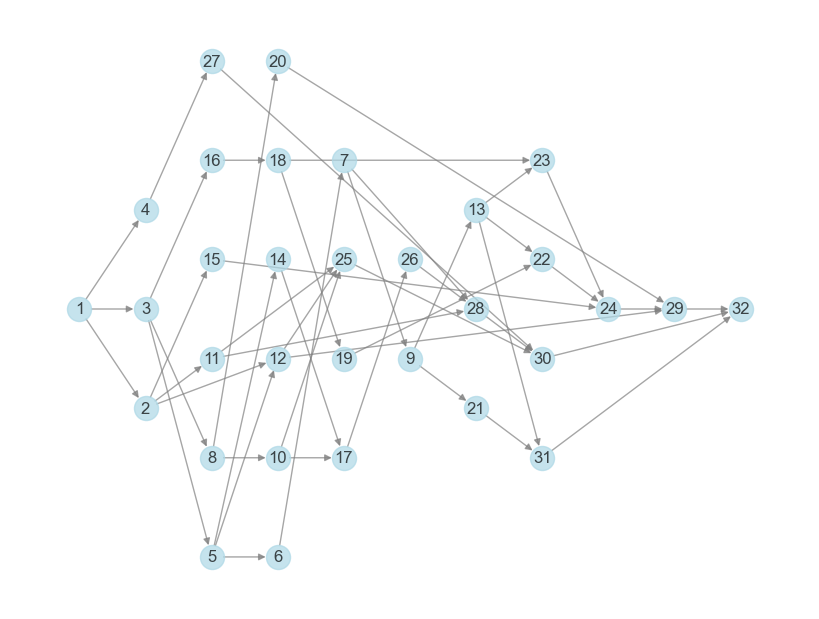

In [6]:
# Create a directed acyclic graph (DAG) from the project file
G=read_sm_file(f'PSPLIB_sample/{filen}')
visualize_dag(G)

In [7]:
# Check topological indices
topological_index=['#Act','CNC', 'OS','SP','AD','LA','I5','TF']
for (z, value) in zip(topological_index,compute_topological_indicators(G)):
    print(f"{z}: {value:0.4f}")

#Act: 30.0000
CNC: 1.4000
OS: 0.3172
SP: 0.2759
AD: 0.3571
LA: 0.0488
I5: 0.6952
TF: 0.3810


In [8]:
# Monte Carlo Simulatio flow

# (1) Create a directed acyclic graph (DAG) from the project file
G=read_sm_file(f'PSPLIB_sample/{psplib_metadata.loc[project_id,"FileName"]}')

# (2) Add beta-PERT distribution parameters
# Assume a skewed left distribution for the risk relative to baseline duration
add_risk_parameters(G, optim=0.8, mostprob=1.1, pessim=1.2)

# (3) Set up the control point at EV=15%
evaluate_at_EV(G, EV=0.15, Ti=0, N=10000)  

# (4) Monte Carlo simulaton from the control point
# draw_random_durations(G,control=True)
simulation(G, project_name=psplib_metadata.loc[project_id,'FileName'].replace('.sm',''), 
           experiment='00test', control=True, Nruns=1000, echo=False, output_dir='./test')


In [9]:
# Read simulation results
simulation_results = pd.read_csv('./test/'+psplib_metadata.loc[project_id,'FileName'].replace('.sm','')+'_simulation_' + '00test'+ '.csv',index_col=0)

In [11]:
# Distribution statistics of ended jobs at the control point
for c in [f'duration{n}' for n in G.nodes() if G.nodes[n]['done%']>=1][1:]:
    print(c, f'mean: {simulation_results[c].mean():.2f}, std: {simulation_results[c].std():.2f}')

duration3 mean: 4.27, std: 0.00
duration4 mean: 2.13, std: 0.00
duration5 mean: 1.07, std: 0.00


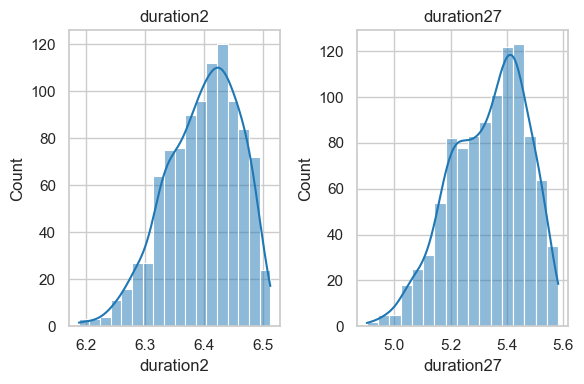

In [12]:
#  Distribution statistics of started but incomplete activities at the control point
vars = [f'duration{n}' for n in G.nodes() if (G.nodes[n]['done%']>0.5) and (G.nodes[n]['done%']<1)]
m=len(vars)
fig, axes = plt.subplots(1, m, figsize=(6, 4))
for ax, col in zip(axes.flat, vars):
    sns.histplot(simulation_results[col], ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()

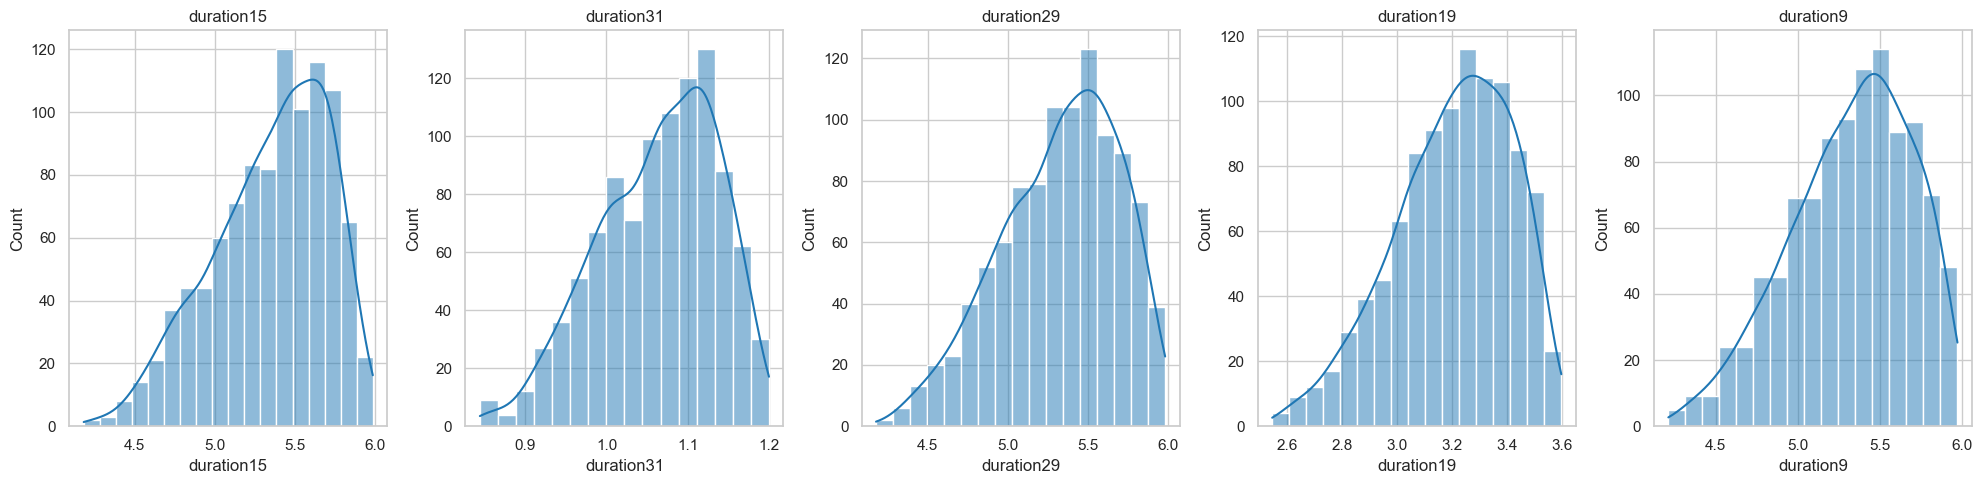

In [13]:
#  Distribution statistics of not started activities at the control point
vars = random.sample([f'duration{n}' for n in G.nodes() if G.nodes[n]['done%']==0][:-1],5)
m=len(vars)
fig, axes = plt.subplots(1, m, figsize=(20, 5))
for ax, col in zip(axes.flat, vars):
    sns.histplot(simulation_results[col], ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Monte Carlo simulations

In [ ]:
# for project_id in psplib_metadata[psplib_metadata['sample']].index:
        
#     # (1) Create a directed acyclic graph (DAG) from the project file
#     G=read_sm_file(f'data/psplib_sample/{psplib_metadata.loc[project_id,"FileName"]}')

#     # (2) Add beta-PERT distribution parameters
#     # Assume a skewed left distribution for the risk relative to baseline duration
#     add_risk_parameters(G, optim=0.8, mostprob=1.1, pessim=1.2)

#     # (3) Set up the control point at EV=15%
#     evaluate_at_EV(G, EV=0.15, Ti=0, N=10000)  

#     # (4) Monte Carlo simulaton from the control point
#     # draw_random_durations(G,control=True)
#     simulation(G, project_name=psplib_metadata.loc[project_id,'FileName'].replace('.sm',''), experiment='01', control=True, Nruns=10000, echo=True)


Starting simulation of j1201_3...
Starting simulation of j1201_4...
Starting simulation of j1201_9...
Starting simulation of j1202_2...
Starting simulation of j1203_1...
Starting simulation of j1204_7...
Starting simulation of j1204_8...
Starting simulation of j1204_9...
Starting simulation of j1205_2...
Starting simulation of j1206_10...
Starting simulation of j1207_3...
Starting simulation of j1208_1...
Starting simulation of j1209_7...
Starting simulation of j12010_6...
Starting simulation of j12010_7...
Starting simulation of j12011_2...
Starting simulation of j12012_3...
Starting simulation of j12012_4...
Starting simulation of j12013_1...
Starting simulation of j12013_9...
Starting simulation of j12013_10...
Starting simulation of j12014_5...
Starting simulation of j12014_7...
Starting simulation of j12014_10...
Starting simulation of j12015_2...
Starting simulation of j12016_3...
Starting simulation of j12016_7...
Starting simulation of j12018_3...
Starting simulation of j12018_

In [19]:
for subset in ["j30","j60","j90","j120"]:
    print(f"{subset}: {len([f for f in os.listdir('./montecarlo') if f.startswith(subset)])}")

j30: 100
j60: 100
j90: 100
j120: 100


## Model selection and model evaluation dataset

In [30]:
seed=112358
random.seed(seed)

In [31]:
psplib_metadata['model_selection']=False
for subset in psplib_metadata['SubSet'].unique():
    psplib_metadata.loc[ psplib_metadata[(psplib_metadata['sample'] == True) & (psplib_metadata['SubSet'] == subset)].sample(10, random_state=seed).index, 'model_selection'] = True

In [32]:
psplib_metadata[psplib_metadata['sample']==True].groupby(['SubSet']).agg({'sample':'sum','model_selection':'sum'})

,sample,model_selection
SubSet,,
J120,100,10
J30,100,10
J60,100,10
J90,100,10


In [39]:
psplib_metadata.loc[psplib_metadata['model_selection']==True, 
                    ['SubSet','FileName','sample','model_selection']].to_csv('./model_selection/project_selection.csv')

In [41]:
psplib_metadata.loc[psplib_metadata['model_selection']==False, 
                    ['SubSet','FileName','sample','model_selection']].to_csv('./model_evaluation/project_evaluation.csv')

## Cross-Validation sets
Indexes for all datasets (model selection and model evaluation)

In [ ]:
# Sample 20% of a simulation run for testing (the rest will be used for training)
# The number of runs is 
Nruns=10000
random.seed(seed)
pd.DataFrame(random.sample(range(Nruns),int(Nruns*0.2)), columns=['test_runs']).to_csv('./montecarlo/test_runs.csv', index=False)